                        Informe de la etapa 1

se carga el archivo JSON de satelites, observando la totalidad de los registros hechos y sus caracteristicas.

In [1]:
from catalogo import leer_satelites, contar_por_grupo, lanzamientos_por_anio
from satelite import __str__, crear_satelites
from datetime import datetime
import analisis

ruta = "datos/satelites.json"
registros = leer_satelites(ruta)
print("registro total:", len(registros))
epoch= registros[0].get('EPOCH')
print("fecha de los datos 'EPOCH':", epoch)
actual= datetime.now()
l_satelites= crear_satelites(registros, actual)
descartados= len(registros) - len(l_satelites)
print("los satelites descartados por crear_satelites:", descartados)


registro total: 16822
fecha de los datos 'EPOCH': 2026-10-27T03:45:44.572896
los satelites descartados por crear_satelites: 135


se agruparon los satelites segun su informacion para saber su distribucion y ademas para poder calcular el porcentaje de los satelites Starlink

In [2]:
conteo_grupos= contar_por_grupo(registros)
print("satelites por grupo:")
for grupo, cantidad in conteo_grupos.items():
    print(f'{grupo} : {cantidad}')

cant_starlink= conteo_grupos.get("Starlink", 0)
procentaje_strlink= (cant_starlink / len(registros)) * 100 if len (registros) > 0 else 0
print("el porcentaje total de Starlink", procentaje_strlink)


satelites por grupo:
otros : 4152
GPS : 40
Globalstar : 36
BeiDou : 55
Iridium : 80
OneWeb : 651
Starlink : 11160
Qianfan : 257
Kuiper : 391
el porcentaje total de Starlink 66.34169539888242


a partir de identificarlos, se evaluo la cantidad de satelites lanzados desde 2015 para saber el año con mas lanzamientos que hubo

In [3]:
print("lanzamineto por año:")
        
anio_max= ""
max_cant= 0

dts_anios= lanzamientos_por_anio(registros)

for anio in sorted(dts_anios):
    if int(anio) >= 2015:
        cantidad = dts_anios[anio]
        print(f" año {anio} : {cantidad}")
        if cantidad > max_cant:
            max_cant = cantidad
            anio_max = anio

print()

lanzamineto por año:
 año 2015 : 96
 año 2016 : 84
 año 2017 : 136
 año 2018 : 193
 año 2019 : 144
 año 2020 : 354
 año 2021 : 987
 año 2022 : 1715
 año 2023 : 2260
 año 2024 : 2428
 año 2025 : 4289
 año 2026 : 3421



se clasifican los satelites segun su regimen ortbital(LEO, MEO, GEO, HEO) utilizando las altitudes actuales

In [4]:
momento_actual= datetime.now()

l_satelites= crear_satelites(registros, momento_actual)
print(f"se crearon {len(l_satelites)} satelites validos")

tipos_orbita= analisis.contar_por_tipo(l_satelites)
print("agrupacion segun el tipo de orbita:")
for orbita, cant in tipos_orbita.items():
    print(f"{orbita} : {cant}")

se crearon 16687 satelites validos
agrupacion segun el tipo de orbita:
LEO : 15877
MEO : 197
GEO : 590
HEO : 23


se identifica los satelites de mayor y menor altitud, para hacer luego un top 10 de cada uno

In [5]:

alto = analisis.mas_alto(l_satelites)
bajo = analisis.mas_bajo(l_satelites)
print("satelite mas alto:", alto)
print("satelite mas bajo:", bajo)

def obtener_altitud(satelite):
    return satelite.altitud

top_altos= sorted(l_satelites, key=obtener_altitud, reverse=True)
for i in range(min(10, len(top_altos))):
    print("top de 10 altos:")
    print(top_altos[i])

top_bajos= sorted(l_satelites, key=obtener_altitud)
for i in range(min(10, len(top_bajos))):
    print("top de 10 bajos:")
    print(top_bajos[i])


satelite mas alto: MMS 2 | HEO | 157800.446 km
satelite mas bajo: STARLINK-1478 | LEO | 100.923 km
top de 10 altos:
MMS 2 | HEO | 157800.446 km
top de 10 altos:
MMS 3 | HEO | 157797.25 km
top de 10 altos:
MMS 1 | HEO | 157786.718 km
top de 10 altos:
MMS 4 | HEO | 157772.275 km
top de 10 altos:
SMILE | HEO | 80417.354 km
top de 10 altos:
THEMIS A | HEO | 77854.922 km
top de 10 altos:
XMM-NEWTON | HEO | 67691.779 km
top de 10 altos:
CXO | HEO | 66666.837 km
top de 10 altos:
PROBA-3 CSC | HEO | 53750.011 km
top de 10 altos:
PROBA-3 OSC | HEO | 53748.413 km
top de 10 bajos:
STARLINK-1478 | LEO | 100.923 km
top de 10 bajos:
STARLINK-1762 | LEO | 101.596 km
top de 10 bajos:
RASSVET-3 17 | LEO | 101.773 km
top de 10 bajos:
STARLINK-1554 | LEO | 112.563 km
top de 10 bajos:
2022-098C | LEO | 113.129 km
top de 10 bajos:
STARLINK-38373 | LEO | 113.771 km
top de 10 bajos:
SWIFT | LEO | 115.807 km
top de 10 bajos:
STARLINK-2566 | LEO | 116.622 km
top de 10 bajos:
STARLINK-36163 | LEO | 125.45 km
to

se genera un resumen de las altitudes (cantidad, minmia, maxima y media)

In [6]:
resumen_g= {
    "LEO": [],
    "MEO": [],
    "GEO": [],
    "HEO": []
}

for satelite in l_satelites:
    tipo = satelite.tipo_orbita()
    if tipo in resumen_g:
        resumen_g[tipo].append(satelite.altitud)

for grupo, altitudes in resumen_g.items():
    cantidad = len(altitudes)
    if cantidad > 0:
        minima= min(altitudes)
        maxima= max(altitudes)
        promedio= sum(altitudes)/ cantidad
    else:
        minima= 0
        maxima= 0
        promedio= 0

print("cantidad:", cantidad)
print("altitud maxima:", maxima)
print("altitud minima", minima)
print("promedio:", promedio)



cantidad: 23
altitud maxima: 157800.446
altitud minima 37094.767
promedio: 69181.618


se filtra unicamente el satelite que este en dentro de las coordenadas (sacada de internet) sobre la zona de bariloche 

In [7]:
zona_bariloche = (-76.30, -46.13, -66.30, -36.13) 
satelites_bariloche= []
for satelite in l_satelites:
    if satelite.esta_en_zona(zona_bariloche):
        satelites_bariloche.append(satelite)

bariloche_ord= sorted(satelites_bariloche, key= obtener_altitud)
for sat in bariloche_ord:
    print(sat)

STARLINK-30235 | LEO | 303.535 km
STARLINK-11635 [DTC] | LEO | 358.596 km
STARLINK-11237 [DTC] | LEO | 359.178 km
GLOBAL-16 | LEO | 405.022 km
STARLINK-35912 | LEO | 472.357 km
STARLINK-35380 | LEO | 473.021 km
STARLINK-36677 | LEO | 473.469 km
STARLINK-37371 | LEO | 474.101 km
STARLINK-38055 | LEO | 474.985 km
STARLINK-35348 | LEO | 475.941 km
STARLINK-4727 | LEO | 476.285 km
STARLINK-3602 | LEO | 477.145 km
STARLINK-32389 | LEO | 477.478 km
STARLINK-5174 | LEO | 477.716 km
STARLINK-37977 | LEO | 478.511 km
STARLINK-37443 | LEO | 478.55 km
STARLINK-30913 | LEO | 479.145 km
STARLINK-35254 | LEO | 479.224 km
STARLINK-37410 | LEO | 479.521 km
STARLINK-37292 | LEO | 480.021 km
STARLINK-38227 | LEO | 480.281 km
STARLINK-37968 | LEO | 480.938 km
STARLINK-34748 | LEO | 481.219 km
STARLINK-3277 | LEO | 481.798 km
STARLINK-38232 | LEO | 482.118 km
STARLINK-34006 | LEO | 485.548 km
STARLINK-37969 | LEO | 485.937 km
STARLINK-4695 | LEO | 485.997 km
STARLINK-36209 | LEO | 488.63 km
STARLINK-33942

Conslusiones:

a lo largo de este proceso, se filtro y analizo por completo los satelites de 'satelites.json', para haber obtenido:

-las clasificaciones y distribuciones de los satelites 
-a partir de los los lanzamientos registrados, se observo la actividad de los ultimos años (desde el 2015)
-mediante el metodo de 'esta_en_zona' junto con las funciones de ordeamiento y el '__str__', fue posible visualizar especificamente un satelite en la region de bariloche.

                                    ETAPA 2

**Lanzamientos por año**: barras por año y barras apiladas Starlink vs. resto, de 1990 a 2026. 

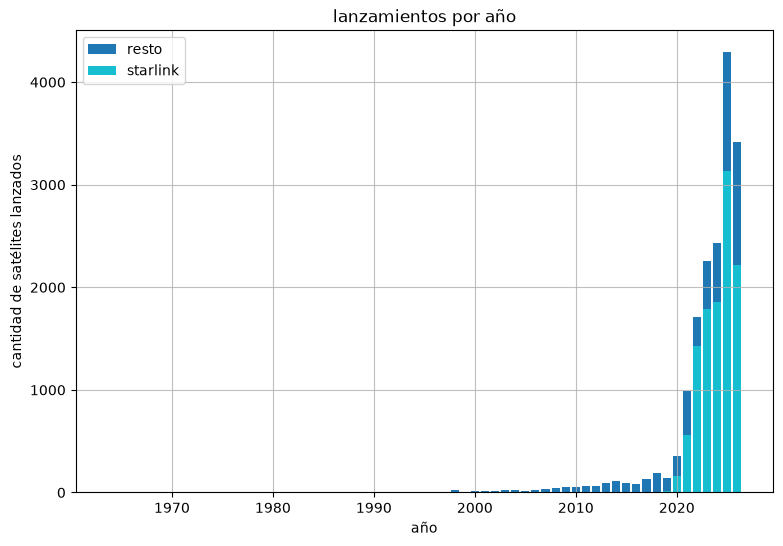

In [8]:
import matplotlib.pyplot as plt

registro_starlink= [i for i in registros if "starlink" in str(i.get("OBJECT_NAME", "")).lower()]
registro_resto= [r for r in registros if "starlink" not in str(r)]

datos_s= lanzamientos_por_anio(registro_starlink)
datos_r= lanzamientos_por_anio(registro_resto)

totales= sorted(list(set(list(datos_s.keys())+ list(datos_r.keys()))), key= int)
cant_s=[datos_s.get(anio, 0) for anio in totales]
cant_r=[datos_r.get(anio, 0) for anio in totales]

plt.figure(figsize=(9,6))
plt.grid(alpha=0.8)
plt.bar(totales, cant_r, label= "resto", color= "C0")
plt.bar(totales, cant_s, label= "starlink", color= "C9")
plt.title("lanzamientos por año")
plt.xlabel("año")
plt.ylabel("cantidad de satélites lanzados")
plt.legend()
plt.show()

**Altura media por grupo**: ¿qué grupos están en órbita baja y cuáles más arriba?

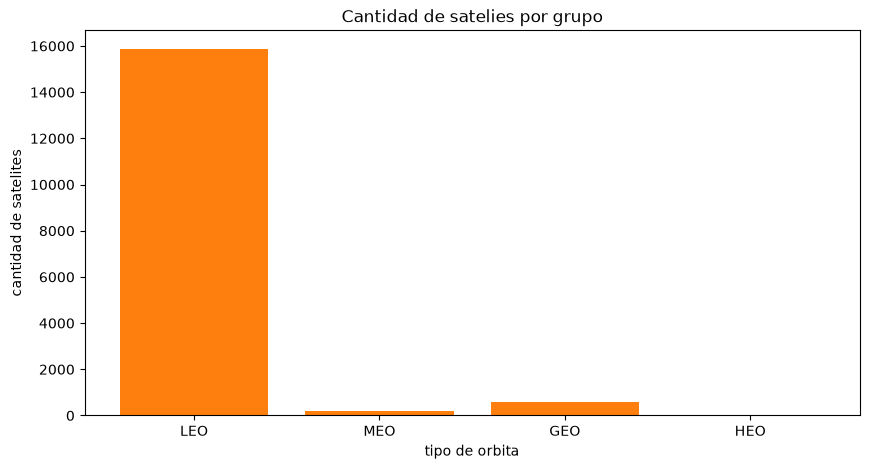

In [9]:
orbitas= list(resumen_g.keys())
cantidades= [len(altitudes) for altitudes in resumen_g.values()]

plt.figure(figsize=(10,5))
plt.bar(orbitas, cantidades, color="C1")
plt.title("Cantidad de satelies por grupo")
plt.xlabel("tipo de orbita")
plt.ylabel("cantidad de satelites")
plt.show()



altitudes

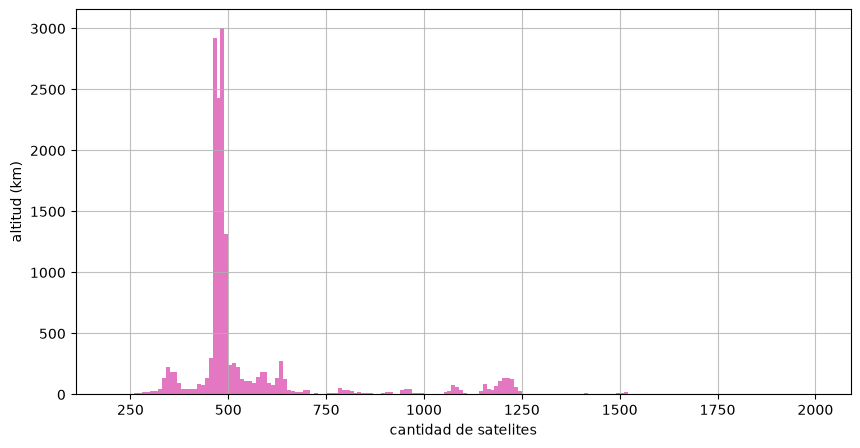

In [10]:
import numpy as np
altitudes_t= [j for lista in resumen_g.values() for j in lista]
ancho_bin= 10
lineales= np.arange(200, 2000 + ancho_bin, ancho_bin)
plt.figure(figsize=(10,5))
plt.hist(altitudes_t, bins= lineales, color= "C6")
plt.ylabel("altitud (km)")
plt.xlabel("cantidad de satelites")
plt.grid(alpha= 0.8)
plt.show()

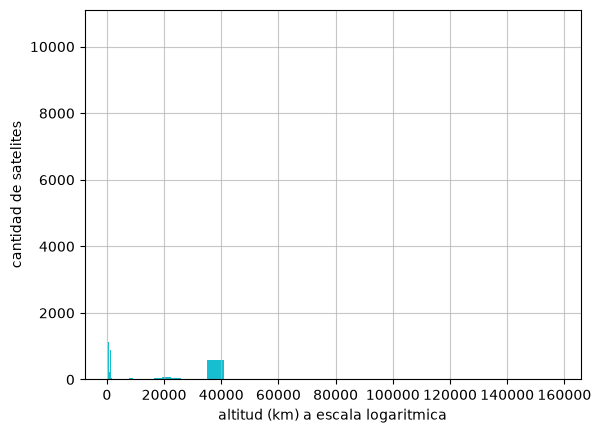

In [11]:
min_alti= max(min(altitudes_t), 1)
max_alti= max(altitudes_t)

bins_log= np.logspace(np.log10(min_alti), np.log10(max_alti), 50)
plt.hist(altitudes_t, bins=bins_log, color="C9")
plt.xlabel("altitud (km) a escala logaritmica")
plt.ylabel("cantidad de satelites")
plt.grid(alpha= 0.7)
plt.show()

Inclinaciones

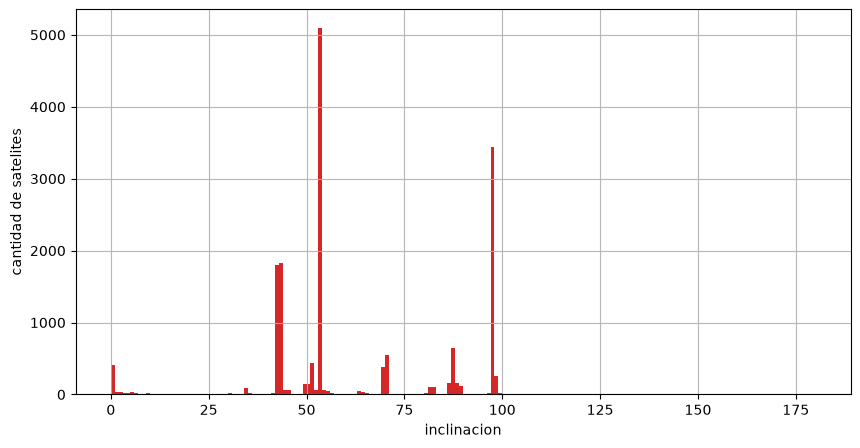

In [15]:
inclinaciones= [float(r['INCLINATION']) for r in registros]
bins_inclinacion= np.arange(0, 180 + 1, 1)

plt.figure(figsize=(10, 5))
plt.hist(inclinaciones, bins_inclinacion, color="C3")
plt.xlabel("inclinacion")
plt.ylabel("cantidad de satelites")
plt.grid(alpha= 0.9)
plt.show()